# Melbourne Airport: baggage handling evidence review
**Md Tanvir Rahman · Analytics portfolio**

[Interactive website](https://luggage.tanvirrahman.dev/) · [Original evidence tables](../dist/assets/study-evidence.pdf) · [Summary CSV](../dist/assets/terminal-summary.csv)

This notebook rebuilds descriptive charts and percentage changes from the supplied KIT714 quantitative research report. It contains **executed Python cells and saved chart outputs**, so visitors can read the results directly on GitHub.

**Scope:** daily summary means for four terminals in 2018 and 2019, transcribed from Figures 1 and 2 (printed pp. 5–6). The original daily observations and analysis files were not supplied. This is a new summary-data notebook, not the report's original analysis notebook. Statistical tests below are transcribed outputs, not rerun tests. Time units are unspecified in the report tables; no conversion to minutes or seconds is made.

## 1. Load and validate the transcribed summary data

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd()
if not (root / "dist/assets/terminal-summary.csv").exists():
    root = root.parent
csv_path = root / "dist/assets/terminal-summary.csv"
df = pd.read_csv(csv_path).set_index("terminal")
assert list(df.index) == ["T1", "T2", "T3", "T4"]
measurements = ["mean_time_2018_source_units", "mean_time_2019_source_units", "mean_daily_bags_2018", "mean_daily_bags_2019"]
assert df[measurements].notna().all().all()
assert (df[measurements] > 0).all().all()
print("Source: transcribed report means; four terminals, two years. No raw daily records.")
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")
display(df[measurements].round(3))

Source: transcribed report means; four terminals, two years. No raw daily records.
Python 3.9.6 | pandas 2.3.3 | matplotlib 3.9.4


,mean_time_2018_source_units,mean_time_2019_source_units,mean_daily_bags_2018,mean_daily_bags_2019
terminal,,,,
T1,4.769,4.952,4529.882,4699.263
T2,4.274,3.809,14734.899,13112.847
T3,7.604,6.670,4758.167,5307.622
T4,7.170,7.137,3669.496,2798.962


## 2. Calculate changes from the displayed means

Percentage change = `(2019 mean − 2018 mean) / 2018 mean × 100`.

A negative time change means earlier average first-bag arrival. A volume change describes workload; it is not itself an efficiency improvement or a measure of capacity. Percentages are recalculated here rather than treating the report's t-statistics as seconds saved.

In [2]:
df["time_change_pct_recalculated"] = (df["mean_time_2019_source_units"] / df["mean_time_2018_source_units"] - 1) * 100
df["volume_change_pct"] = (df["mean_daily_bags_2019"] / df["mean_daily_bags_2018"] - 1) * 100
assert np.allclose(df["time_change_pct_recalculated"], df["time_change_pct"], atol=0.0001)
summary = df[["time_change_pct_recalculated", "volume_change_pct"]].rename(columns={"time_change_pct_recalculated":"Arrival time change (%)", "volume_change_pct":"Daily volume change (%)"})
display(summary.round(1))

,Arrival time change (%),Daily volume change (%)
terminal,,
T1,3.8,3.7
T2,-10.9,-11.0
T3,-12.3,11.5
T4,-0.5,-23.7


## 3. Compare arrival time and workload

Both plots start at zero and use common scales across terminals. Values are annual means of the daily metrics, not individual flights or bag journeys. The automation classification follows the report's study scenario; the historical installation date has not been independently verified.

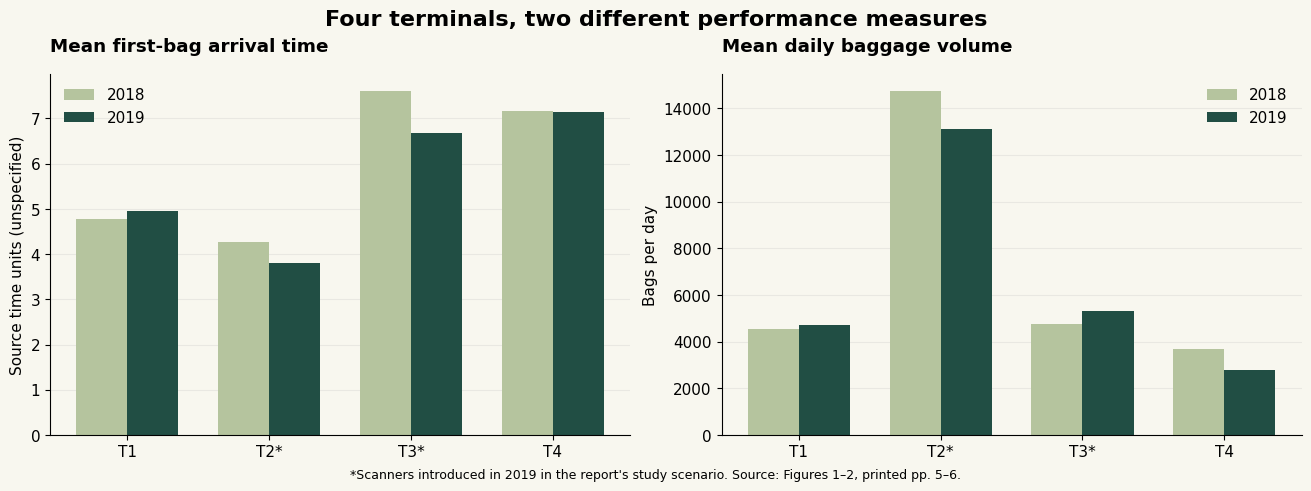

In [3]:
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11, "axes.spines.top":False, "axes.spines.right":False, "figure.facecolor":"#f8f7ef", "axes.facecolor":"#f8f7ef"})
colors = ["#b5c49e", "#214e44"]
figures = root / "notebooks/figures"
figures.mkdir(exist_ok=True)
x = np.arange(len(df))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for ax, a, b, title, ylabel in [(axes[0], "mean_time_2018_source_units", "mean_time_2019_source_units", "Mean first-bag arrival time", "Source time units (unspecified)"), (axes[1], "mean_daily_bags_2018", "mean_daily_bags_2019", "Mean daily baggage volume", "Bags per day")]:
    ax.bar(x-.18, df[a], width=.36, color=colors[0], label="2018")
    ax.bar(x+.18, df[b], width=.36, color=colors[1], label="2019")
    ax.set_xticks(x, ["T1", "T2*", "T3*", "T4"])
    ax.set_title(title, loc="left", fontweight="bold", pad=16)
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
fig.suptitle("Four terminals, two different performance measures", fontsize=16, fontweight="bold")
fig.supxlabel("*Scanners introduced in 2019 in the report's study scenario. Source: Figures 1–2, printed pp. 5–6.", fontsize=9)
fig.savefig(figures / "terminal_comparisons.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Read time change alongside volume change

T3 combines lower average arrival time with higher daily volume. T2 records lower time alongside lower daily volume. These are descriptive associations, not estimates of automation's causal effect. With only four aggregate points, a correlation or fitted trend line would add little evidence.

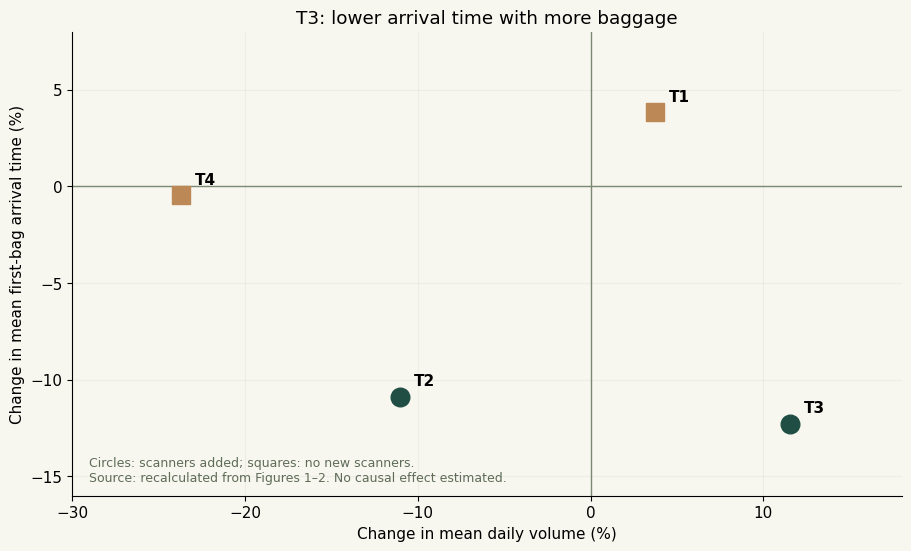

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.4), layout="constrained")
for terminal, row in df.iterrows():
    automated = terminal in ["T2", "T3"]
    ax.scatter(row["volume_change_pct"], row["time_change_pct_recalculated"], s=180, c="#214e44" if automated else "#bc8956", marker="o" if automated else "s", zorder=3)
    ax.annotate(terminal, (row["volume_change_pct"], row["time_change_pct_recalculated"]), xytext=(10, 8), textcoords="offset points", fontweight="bold")
ax.axhline(0, color="#7b8873", lw=1)
ax.axvline(0, color="#7b8873", lw=1)
ax.set(xlabel="Change in mean daily volume (%)", ylabel="Change in mean first-bag arrival time (%)", title="T3: lower arrival time with more baggage")
ax.set_xlim(-30, 18)
ax.set_ylim(-16, 8)
ax.text(.02, .03, "Circles: scanners added; squares: no new scanners.\nSource: recalculated from Figures 1–2. No causal effect estimated.", transform=ax.transAxes, fontsize=9, color="#5e6c58")
ax.grid(alpha=.15)
fig.savefig(figures / "time_vs_workload_change.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Statistical results reported in the PDF

The following table is **transcribed evidence**, not the output of tests run on the original observations. It is kept separate from the calculations above. A t-statistic is dimensionless and is not a time saving. The T4 discussion uses outputs with inconsistent T2 captions in section 3.3.

In [5]:
reported = pd.DataFrame([
    ["Across terminals", "Kruskal–Wallis", "H = 2455.110; df = 3", "< .001", "Figure 17, printed p. 20"],
    ["T2: 2019 vs 2018", "Paired t-test", "t = -42.829; df = 364", "< .001", "Figure 20, printed p. 22"],
    ["T3: 2019 vs 2018", "Paired t-test", "t = -47.002; df = 364", "< .001", "Figure 20, printed p. 22"],
    ["T1: year comparison", "ANOVA", "F = 182.682; df = 1, 728", "< .001", "Figure 22, printed p. 25"],
    ["T4: year comparison (section context)", "ANOVA", "F = 2.927; df = 1, 728", ".088", "Figure 24, printed p. 25; caption says T2"]
], columns=["Comparison", "Reported test", "Reported statistic", "Reported p", "Source"])
display(reported)
print("These tests were not rerun. The original daily observations were not supplied.")

,Comparison,Reported test,Reported statistic,Reported p,Source
0,Across terminals,Kruskal–Wallis,H = 2455.110; df = 3,< .001,"Figure 17, printed p. 20"
1,T2: 2019 vs 2018,Paired t-test,t = -42.829; df = 364,< .001,"Figure 20, printed p. 22"
2,T3: 2019 vs 2018,Paired t-test,t = -47.002; df = 364,< .001,"Figure 20, printed p. 22"
3,T1: year comparison,ANOVA,"F = 182.682; df = 1, 728",< .001,"Figure 22, printed p. 25"
4,T4: year comparison (section context),ANOVA,"F = 2.927; df = 1, 728",.088,"Figure 24, printed p. 25; caption says T2"


These tests were not rerun. The original daily observations were not supplied.


## 6. Interpretation audit and next steps

- **T1:** the mean increases from 4.769 to 4.952 (+3.8%). That indicates a longer arrival time, contrary to the report narrative describing improvement.
- **T2:** the mean time decreases by 10.9%, with mean daily volume down 11.0%. Workload is an important possible explanation.
- **T3:** the mean time decreases by 12.3%, while mean daily volume rises 11.5%. This is a useful candidate for deeper investigation, not proof of the scanners' effect.
- **T4:** the mean time decreases by about 0.5%; reported p = .088 does not establish a change at the .05 threshold and does not prove equivalence.
- **Assumptions:** inspect paired differences, pairing rules, serial dependence and missingness using raw records. The displayed Tukey comparisons should be checked against a rank-based post hoc procedure following Kruskal–Wallis.
- **A stronger follow-up:** validate units and rollout dates, model volume, staffing, flights and seasonality, and consider difference-in-differences only after examining comparison-group suitability and pre-trends. Report effect sizes and uncertainty, as well as high-percentile first- and last-bag times.

### Reproduce this notebook

From the repository root, install `notebooks/requirements.txt`, then open this notebook in Jupyter. The notebook locates the supplied summary CSV from either the repository root or the notebooks directory. Figures are saved to `notebooks/figures/`. No external data service or credentials are needed.

The website's interactive baggage sandbox is a separate illustrative model and is not used to generate any of these study findings.